# HEIAuthRisk — Public Results Analysis

This notebook reproduces the **descriptive results of Article 1 using only the public release** of HEIAuthRisk.

## Scope

The notebook requires only `HEIAuthRisk_public.csv` and does **not** access the restricted dataset, raw logs, institutional identifiers, exact timestamps, the institutional `network_pseudo_id`, HMAC keys, or administrative credentials.

It reproduces public descriptive results related to dataset size, actor activity, provider-generated suspiciousness, authentication characteristics, geographic distribution, monthly coverage, and missingness of the **42 public attributes**.

`actor_network_id` is public and actor-scoped; it does not provide a cross-actor network join key. Institutional characterization remains excluded because `institution_pseudo_id` is restricted.


## 1. Environment and public dataset

In [8]:
from pathlib import Path
import os
import json
import math
import hashlib

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

EXPECTED_PUBLIC = [
    "event_id",
    "actor_pseudo_id",
    "event_time_hour_utc",
    "event_hour",
    "day_of_week",
    "month",
    "is_weekend",
    "prior_event_count",
    "hours_since_last_login",
    "hours_since_first_login",
    "logins_24h",
    "logins_7d",
    "logins_30d",
    "login_rate_30d",
    "active_days_30d",
    "actor_network_id",
    "ip_version",
    "is_new_ip",
    "ip_changed",
    "distinct_networks_24h",
    "distinct_networks_7d",
    "distinct_networks_30d",
    "networks_seen_to_date",
    "ip_country",
    "continent",
    "is_new_country",
    "country_changed",
    "is_new_continent",
    "continent_changed",
    "distinct_countries_24h",
    "distinct_countries_7d",
    "distinct_countries_30d",
    "distinct_countries_to_date",
    "login_type",
    "login_challenge_method",
    "is_new_login_type",
    "login_type_changed",
    "is_new_challenge",
    "challenge_changed",
    "distinct_login_types_30d",
    "distinct_challenges_30d",
    "provider_suspicious",
]

# Public repository default. You may override it with:
# HEIAuthRisk_PUBLIC_CSV=/path/to/file.csv
configured = os.getenv("HEIAuthRisk_PUBLIC_CSV")
candidates = []
if configured:
    candidates.append(Path(configured))

candidates += [
    Path("data/HEIAuthRisk_public_v1.csv"),
    Path("../data/HEIAuthRisk_public_v1.csv"),
    Path("HEIAuthRisk_public_v1.csv"),
]

PUBLIC_FILE = next((p for p in candidates if p.exists()), None)
print(f"Using public CSV: {PUBLIC_FILE}")
if PUBLIC_FILE is None:
    raise FileNotFoundError(
        "Public CSV not found. Place HEIAuthRisk_public_v1.csv in data/ "
        "or define HEIAuthRisk_PUBLIC_CSV."
    )

OUTPUT_DIR = Path("outputs/article_one_results")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

public = pd.read_csv(PUBLIC_FILE, low_memory=False)

if list(public.columns) != EXPECTED_PUBLIC:
    raise ValueError(
        f"Expected exactly 42 public attributes in the v1.0 schema; found {len(public.columns)}.\n"
        f"Columns found: {list(public.columns)}"
    )

public["event_time_hour_utc"] = pd.to_datetime(
    public["event_time_hour_utc"], utc=True, errors="raise"
)
public["provider_suspicious"] = pd.to_numeric(
    public["provider_suspicious"], errors="raise"
).astype(int)

with open(PUBLIC_FILE, "rb") as f:
    public_sha256 = hashlib.sha256(f.read()).hexdigest()

print(f"Public file: {PUBLIC_FILE.resolve()}")
print(f"Rows: {len(public):,}")
print(f"Columns: {len(public.columns)}")
print(f"SHA-256: {public_sha256}")

Using public CSV: ..\data\HEIAuthRisk_public_v1.csv
Public file: E:\Developer\HEIAuthRisk\public\data\HEIAuthRisk_public_v1.csv
Rows: 73,527
Columns: 42
SHA-256: 66ebaf1475eb16453180c50f565cd3f46877fe936cac5ec7c6449d6e841e0fe7


## 2. Dataset overview

In [9]:
n_events = len(public)
n_actors = public["actor_pseudo_id"].nunique()
flagged = int(public["provider_suspicious"].sum())
not_flagged = int((public["provider_suspicious"] == 0).sum())
flagged_pct = flagged / n_events * 100

public_time_min = public["event_time_hour_utc"].min()
public_time_max = public["event_time_hour_utc"].max()

overview = pd.DataFrame([
    ["Authentication events", n_events],
    ["Pseudonymized actors", n_actors],
    ["Public attributes", len(public.columns)],
    ["Provider flagged events", flagged],
    ["Provider not-flagged events", not_flagged],
    ["Provider flagged proportion (%)", flagged_pct],
    ["Public time coverage start (hour UTC)", public_time_min.isoformat()],
    ["Public time coverage end (hour UTC)", public_time_max.isoformat()],
], columns=["metric", "value"])

overview.to_csv(OUTPUT_DIR / "dataset_overview.csv", index=False)
overview

,metric,value
0,Authentication events,73527
1,Pseudonymized actors,12190
2,Public attributes,42
3,Provider flagged events,7196
4,Provider not-flagged events,66331
5,Provider flagged proportion (%),9.7869
6,Public time coverage start (hour UTC),2025-12-19T19:00:00+00:00
7,Public time coverage end (hour UTC),2026-08-12T16:00:00+00:00


The public timestamp is generalized to the hour. Therefore, the temporal limits above describe the **publicly observable coverage**, not the exact second/millisecond boundaries retained in the restricted schema. Network, country, and authentication-diversity features based on `event_time_hour_utc` can be recomputed from the public release; exact login-count windows and exact-hour intervals cannot.


## 3. Actor activity and observed history

In [23]:
def gini_coefficient(values):
    x = np.sort(np.asarray(values, dtype=float))
    if len(x) == 0 or x.sum() == 0:
        return np.nan
    n = len(x)
    return 2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum()) - (n + 1) / n

actor_counts = public["actor_pseudo_id"].value_counts()
q1, median, q3 = actor_counts.quantile([0.25, 0.50, 0.75])

n_singleton = int((actor_counts == 1).sum())
n_recurrent = int((actor_counts > 1).sum())
with_history = int((public["prior_event_count"] > 0).sum())
without_history = int((public["prior_event_count"] == 0).sum())

top_1_n = max(1, math.ceil(n_actors * 0.01))
top_10_n = max(1, math.ceil(n_actors * 0.10))

actor_summary = pd.DataFrame([
    ["Actors with one event", n_singleton, "actors", n_singleton / n_actors * 100],
    ["Actors with recurrent events", n_recurrent, "actors", n_recurrent / n_actors * 100],
    ["Events with prior observed history", with_history, "events", with_history / n_events * 100],
    ["Events without prior observed history", without_history, "events", without_history / n_events * 100],

    ["Actor events Q1", float(q1), "events/actor", None],
    ["Actor events median", float(median), "events/actor", None],
    ["Actor events Q3", float(q3), "events/actor", None],
    ["Actor events maximum", int(actor_counts.max()), "events/actor", None],

    ["Activity Gini coefficient", gini_coefficient(actor_counts), "index", None],

    ["Event share of top 1% actors",
     actor_counts.nlargest(top_1_n).sum(),
     "events",
     actor_counts.nlargest(top_1_n).sum() / n_events * 100],

    ["Event share of top 10% actors",
     actor_counts.nlargest(top_10_n).sum(),
     "events",
     actor_counts.nlargest(top_10_n).sum() / n_events * 100],

], columns=["metric", "value", "unit", "percent"])

actor_summary_display = actor_summary.copy()

actor_summary_display["percent"] = (
    actor_summary_display["percent"]
    .map(lambda x: f"{x:.4f}" if pd.notna(x) else "—")
)
actor_summary_display


,metric,value,unit,percent
0,Actors with one event,347.0000,actors,2.8466
1,Actors with recurrent events,"11,843.0000",actors,97.1534
2,Events with prior observed history,"61,337.0000",events,83.4211
3,Events without prior observed history,"12,190.0000",events,16.5789
4,Actor events Q1,3.0000,events/actor,—
5,Actor events median,3.0000,events/actor,—
6,Actor events Q3,4.0000,events/actor,—
7,Actor events maximum,"1,846.0000",events/actor,—
8,Activity Gini coefficient,0.5375,index,—
9,Event share of top 1% actors,"22,006.0000",events,29.9291


The Gini coefficient and concentration measures are computed directly from the number of public events per `actor_pseudo_id`. No restricted field is required.

Gini coefficient: 0.54


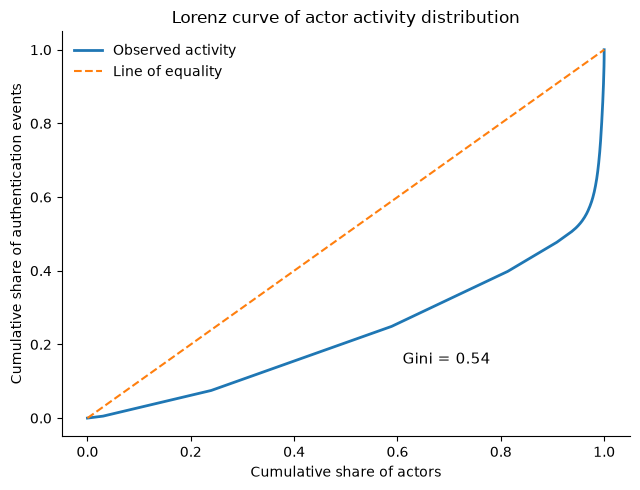

In [24]:
# ============================================================
# Lorenz curve and Gini coefficient
# ============================================================

# Sort from least active to most active actor
x = np.sort(actor_counts)

# Lorenz curve
lorenz = np.insert(np.cumsum(x) / x.sum(),0,0)
population_share = np.linspace(0,1,len(lorenz))   

# Gini coefficient
gini = gini_coefficient(actor_counts)
print(f"Gini coefficient: {gini:.2f}")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

#sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(6.5, 5.0))

ax.plot(population_share,lorenz,linewidth=2,label="Observed activity")
ax.plot([0, 1],[0, 1],linestyle="--",linewidth=1.5,label="Line of equality")
ax.set_xlabel("Cumulative share of actors")
ax.set_ylabel("Cumulative share of authentication events")
ax.set_title("Lorenz curve of actor activity distribution")
ax.text(0.60,0.18,f"Gini = {gini:.2f}",transform=ax.transAxes,fontsize=11)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False,loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "lorenz_activity.pdf",bbox_inches="tight")
fig.savefig(FIGURE_DIR / "lorenz_activity.png",dpi=1000,bbox_inches="tight")
plt.show()

In [25]:
n_events = len(public)
n_actors = public["actor_pseudo_id"].nunique()
actor_counts_series = public["actor_pseudo_id"].value_counts()

top_1_n = max(1,math.ceil(n_actors * 0.01))
top_10_n = max(1,math.ceil(n_actors * 0.10))
top_1_events = actor_counts_series.nlargest(top_1_n).sum()
top_10_events = actor_counts_series.nlargest(top_10_n).sum()
top_1_pct = (top_1_events / n_events * 100)
top_10_pct = (top_10_events / n_events * 100)

print(f"Top 1%: {top_1_events:,} events ({top_1_pct:.4f}%)")
print(f"Top 10%: {top_10_events:,} events ({top_10_pct:.4f}%)")

Top 1%: 22,006 events (29.9291%)
Top 10%: 38,961 events (52.9887%)


## 4. Provider-generated suspiciousness signal

In [15]:
provider_distribution = (
    public["provider_suspicious"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("provider_suspicious")
    .reset_index(name="events")
)
provider_distribution["percent"] = provider_distribution["events"] / n_events * 100

provider_by_history = (
    public.assign(has_prior_history=(public["prior_event_count"] > 0).astype(int))
    .groupby("has_prior_history", dropna=False)["provider_suspicious"]
    .agg(events="size", provider_suspicious_1="sum", provider_suspicious_pct="mean")
    .reset_index()
)
provider_by_history["provider_suspicious_pct"] *= 100

provider_distribution.to_csv(
    OUTPUT_DIR / "provider_suspicious_distribution.csv", index=False
)
provider_by_history.to_csv(
    OUTPUT_DIR / "provider_suspicious_by_history.csv", index=False
)

print("Provider signal distribution")
display(provider_distribution)
print("Provider signal by availability of prior observed history")
display(provider_by_history)

Provider signal distribution


,provider_suspicious,events,percent
0,0,66331,90.2131
1,1,7196,9.7869


Provider signal by availability of prior observed history


,has_prior_history,events,provider_suspicious_1,provider_suspicious_pct
0,0,12190,1531,12.5595
1,1,61337,5665,9.2359


> `provider_suspicious=1` means that the successful authentication event was flagged by the provider. It is **not** treated as confirmed compromise, attack ground truth, or verified malicious activity.

## 5. Authentication characteristics

In [26]:
login_type_table = (
    public["login_type"]
    .fillna("<missing>")
    .value_counts(dropna=False)
    .rename_axis("login_type")
    .reset_index(name="events")
)
login_type_table["percent"] = login_type_table["events"] / n_events * 100

challenge_raw = (
    public["login_challenge_method"]
    .fillna("<missing>")
    .value_counts(dropna=False)
    .rename_axis("login_challenge_method")
    .reset_index(name="events")
)
challenge_raw["percent"] = challenge_raw["events"] / n_events * 100

# Optional token-level view for multi-method values separated by '|'.
challenge_tokens = (
    public["login_challenge_method"]
    .dropna()
    .astype(str)
    .str.split("|")
    .explode()
    .str.strip()
)
challenge_token_table = (
    challenge_tokens[challenge_tokens.ne("")]
    .value_counts()
    .rename_axis("challenge_token")
    .reset_index(name="occurrences")
)
challenge_token_table["percent_of_events"] = challenge_token_table["occurrences"] / n_events * 100

login_type_table.to_csv(OUTPUT_DIR / "login_type_distribution.csv", index=False)
challenge_raw.to_csv(OUTPUT_DIR / "login_challenge_method_distribution.csv", index=False)
challenge_token_table.to_csv(OUTPUT_DIR / "login_challenge_token_distribution.csv", index=False)

print("Login type")
display(login_type_table)
print("Most frequent raw challenge-method values")
display(challenge_raw.head(15))
print("Challenge-method tokens")
display(challenge_token_table.head(15))

Login type


,login_type,events,percent
0,google_password,35452,48.2163
1,reauth,27280,37.1020
2,exchange,10795,14.6817


Most frequent raw challenge-method values


,login_challenge_method,events,percent
0,password,34507,46.9311
1,none,29593,40.2478
2,authenticator_app,5550,7.5482
3,security_key,2539,3.4532
4,password|device_prompt,379,0.5155
5,password|idv_preregistered_phone,279,0.3795
6,device_prompt,185,0.2516
7,idv_preregistered_phone,163,0.2217
8,password|idv_preregistered_email,64,0.0870
9,password|passkey,52,0.0707


Challenge-method tokens


,challenge_token,occurrences,percent_of_events
0,password,35385,48.1252
1,none,29593,40.2478
2,authenticator_app,5550,7.5482
3,security_key,2539,3.4532
4,device_prompt,592,0.8051
5,idv_preregistered_phone,491,0.6678
6,idv_preregistered_email,125,0.1700
7,passkey,95,0.1292
8,idv_any_phone,24,0.0326
9,knowledge_historical_password,20,0.0272


## 6. Geographic characteristics

In [27]:
country_table = (
    public["ip_country"]
    .fillna("<missing>")
    .value_counts(dropna=False)
    .rename_axis("ip_country")
    .reset_index(name="events")
)
country_table["percent"] = country_table["events"] / n_events * 100

country_summary = pd.DataFrame({
    "known_country_values": [int(public["ip_country"].nunique(dropna=True))],
    "missing_country_events": [int(public["ip_country"].isna().sum())],
})

country_table.to_csv(OUTPUT_DIR / "country_distribution.csv", index=False)
country_summary.to_csv(OUTPUT_DIR / "country_summary.csv", index=False)

print(country_summary.to_string(index=False))
display(country_table.head(15))

 known_country_values  missing_country_events
                   23                       3


,ip_country,events,percent
0,Angola,47313,64.3478
1,Brazil,25281,34.3833
2,Portugal,484,0.6583
3,United States,107,0.1455
4,Namibia,59,0.0802
5,Germany,54,0.0734
6,Netherlands,52,0.0707
7,France,42,0.0571
8,Australia,25,0.0340
9,Poland,20,0.0272


The public CSV preserves normalized country values. Rare countries are not replaced by `Other` in the release. Any aggregation into `Other` should be performed only for a specific analysis or presentation.


## 7. Contextual signal synthesis and analytical meaning

The public schema contains several contextual indicators that describe whether the current event introduces a **new** context for the actor or **changes** relative to the immediately previous observed event.

To avoid inflating novelty rates with first-observed events, novelty/change proportions below are computed primarily among events with **prior observed history** (`prior_event_count > 0`). This makes the denominator analytically comparable: there is already an actor history against which the current context can be evaluated.

These indicators are descriptive context signals. They are **not attack labels**, do not constitute a composite risk score, and should not be interpreted as evidence of compromise.


In [18]:

# ============================================================
# Contextual signal synthesis
# ============================================================

prior_mask = public["prior_event_count"] > 0
n_prior = int(prior_mask.sum())

def contextual_binary_row(
    domain,
    signal,
    column,
    meaning,
    mask=None,
):
    if mask is None:
        mask = pd.Series(True, index=public.index)

    s = pd.to_numeric(
        public.loc[mask, column],
        errors="coerce",
    )

    valid = s.notna()
    comparable = int(valid.sum())
    positive = int((s[valid] == 1).sum())
    percent = (
        positive / comparable * 100
        if comparable > 0
        else np.nan
    )

    return {
        "domain": domain,
        "signal": signal,
        "events_with_signal": positive,
        "comparable_events": comparable,
        "percent": percent,
        "analytical_meaning": meaning,
    }


contextual_rows = [
    {
        "domain": "Observed history",
        "signal": "Prior observed history available",
        "events_with_signal": n_prior,
        "comparable_events": n_events,
        "percent": n_prior / n_events * 100,
        "analytical_meaning":
            "The event can be interpreted against earlier observed behavior for the same actor.",
    },

    contextual_binary_row(
        "Network",
        "Previously unseen network",
        "is_new_ip",
        "Current actor-scoped network context had not been observed previously for the actor; this is novelty, not evidence of maliciousness.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Network",
        "Network changed",
        "ip_changed",
        "Current known network differs from the actor's immediately previous observed event.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Geography",
        "Previously unseen country",
        "is_new_country",
        "Current known country had not been observed previously for the actor.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Geography",
        "Country changed",
        "country_changed",
        "Current known country differs from the country of the immediately previous observed event.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Geography",
        "Previously unseen continent",
        "is_new_continent",
        "Current known continent had not been observed previously for the actor.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Geography",
        "Continent changed",
        "continent_changed",
        "Current known continent differs from the continent of the immediately previous observed event.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Authentication",
        "Previously unseen login type",
        "is_new_login_type",
        "Current login type had not been observed previously for the actor.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Authentication",
        "Login type changed",
        "login_type_changed",
        "Current login type differs from the actor's immediately previous observed event.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Authentication",
        "Previously unseen challenge",
        "is_new_challenge",
        "At least one current challenge category had not been observed previously for the actor.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Authentication",
        "Challenge changed",
        "challenge_changed",
        "The normalized set of challenge categories differs from the immediately previous observed event.",
        mask=prior_mask,
    ),

    contextual_binary_row(
        "Provider signal",
        "Provider flagged event",
        "provider_suspicious",
        "Operational suspiciousness signal produced by the provider; not confirmed compromise and not ground truth.",
        mask=None,
    ),
]

contextual_signal_table = pd.DataFrame(contextual_rows)

contextual_signal_table.to_csv(
    OUTPUT_DIR / "contextual_signal_synthesis.csv",
    index=False,
)

contextual_signal_display = contextual_signal_table.copy()
contextual_signal_display["percent"] = (
    contextual_signal_display["percent"]
    .map(lambda x: f"{x:.2f}%" if pd.notna(x) else "—")
)

display(contextual_signal_display)


,domain,signal,events_with_signal,comparable_events,percent,analytical_meaning
0,Observed history,Prior observed history available,61337,73527,83.42%,The event can be interpreted against earlier o...
1,Network,Previously unseen network,25495,61337,41.57%,Current actor-scoped network context had not b...
2,Network,Network changed,29643,61337,48.33%,Current known network differs from the actor's...
3,Geography,Previously unseen country,252,61334,0.41%,Current known country had not been observed pr...
4,Geography,Country changed,605,61331,0.99%,Current known country differs from the country...
5,Geography,Previously unseen continent,187,61334,0.30%,Current known continent had not been observed ...
6,Geography,Continent changed,531,61331,0.87%,Current known continent differs from the conti...
7,Authentication,Previously unseen login type,7836,61337,12.78%,Current login type had not been observed previ...
8,Authentication,Login type changed,16858,61337,27.48%,Current login type differs from the actor's im...
9,Authentication,Previously unseen challenge,13693,61337,22.32%,At least one current challenge category had no...



### Context breadth and intensity

Binary novelty/change indicators show whether a contextual transition occurred. The windowed attributes complement them by describing how broad or intense the recent context was. The median summarizes a typical event, while the 95th percentile exposes the high-activity or high-diversity tail without turning those values into thresholds.


In [28]:

context_profile_specs = [
    ("Activity", "Logins in 24 h", "logins_24h"),
    ("Activity", "Logins in 30 d", "logins_30d"),
    ("Activity", "Active days in 30 d", "active_days_30d"),
    ("Network", "Distinct networks in 30 d", "distinct_networks_30d"),
    ("Geography", "Distinct countries in 30 d", "distinct_countries_30d"),
    ("Authentication", "Distinct login types in 30 d", "distinct_login_types_30d"),
    ("Authentication", "Distinct challenges in 30 d", "distinct_challenges_30d"),
]

context_profile_rows = []

for domain, metric, column in context_profile_specs:
    s = pd.to_numeric(
        public[column],
        errors="coerce",
    ).dropna()

    context_profile_rows.append({
        "domain": domain,
        "metric": metric,
        "median": float(s.median()),
        "q75": float(s.quantile(0.75)),
        "q95": float(s.quantile(0.95)),
        "maximum": float(s.max()),
    })

context_profile_table = pd.DataFrame(
    context_profile_rows
)

context_profile_table.to_csv(
    OUTPUT_DIR / "contextual_profile_summary.csv",
    index=False,
)

display(context_profile_table)


,domain,metric,median,q75,q95,maximum
0,Activity,Logins in 24 h,1.0000,2.0000,6.0000,90.0000
1,Activity,Logins in 30 d,3.0000,18.0000,65.0000,685.0000
2,Activity,Active days in 30 d,2.0000,10.0000,20.0000,28.0000
3,Network,Distinct networks in 30 d,1.0000,3.0000,20.0000,46.0000
4,Geography,Distinct countries in 30 d,1.0000,1.0000,1.0000,7.0000
5,Authentication,Distinct login types in 30 d,1.0000,2.0000,2.0000,3.0000
6,Authentication,Distinct challenges in 30 d,1.0000,2.0000,3.0000,6.0000



### Analytical reading

The synthesis should be read comparatively rather than as a risk model. Most public events have prior observed actor history, so contextual comparison is available for the majority of observations. Network context is comparatively dynamic, whereas country- and continent-level transitions are uncommon among recurrent events. Authentication context lies between these patterns: changes in login type and challenge method occur more often than geographic transitions. The provider flag remains a separate operational signal and should not be conflated with any individual novelty/change indicator.


## 8. Monthly public characterization

In [29]:
monthly = public.assign(
    year_month=public["event_time_hour_utc"].dt.strftime("%Y-%m")
)

monthly_table = (
    monthly.groupby("year_month", sort=True)
    .agg(
        events=("event_id", "size"),
        actors=("actor_pseudo_id", "nunique"),
        provider_suspicious_1=("provider_suspicious", "sum"),
        provider_suspicious_pct=("provider_suspicious", "mean"),
    )
    .reset_index()
)
monthly_table["provider_suspicious_pct"] *= 100

monthly_table.to_csv(OUTPUT_DIR / "monthly_characterization.csv", index=False)
monthly_table

,year_month,events,actors,provider_suspicious_1,provider_suspicious_pct
0,2025-12,1508,368,50,3.3156
1,2026-01,10393,3906,1054,10.1414
2,2026-02,9026,3729,986,10.9240
3,2026-03,9778,4100,909,9.2964
4,2026-04,10516,4208,1094,10.4032
5,2026-05,9733,4177,1018,10.4593
6,2026-06,17961,7090,2021,11.2522
7,2026-07,3172,574,42,1.3241
8,2026-08,1440,411,22,1.5278


Monthly counts describe the **coverage of the public dataset**. Because the public release does not contain `institution_pseudo_id`, this notebook does not reproduce institution-specific monthly coverage and does not interpret monthly counts as behavioral trends.

## 9. Missingness of the 42-attribute public schema


In [30]:
public_missingness = pd.DataFrame({
    "attribute": public.columns,
    "missing": [int(public[c].isna().sum()) for c in public.columns],
})
public_missingness["percent"] = public_missingness["missing"] / n_events * 100

public_missingness.to_csv(OUTPUT_DIR / "missingness_public.csv", index=False)
public_missingness[public_missingness["missing"] > 0].reset_index(drop=True)

,attribute,missing,percent
0,hours_since_last_login,12190,16.5789
1,ip_version,4,0.0054
2,ip_country,3,0.0041
3,continent,3,0.0041
4,is_new_country,3,0.0041
5,country_changed,6,0.0082
6,is_new_continent,3,0.0041
7,continent_changed,6,0.0082


For `hours_since_last_login`, missingness on the first observed event of each actor is structural. Other missing values should be interpreted according to the public data dictionary.

## 10. Publication-ready figures from public data

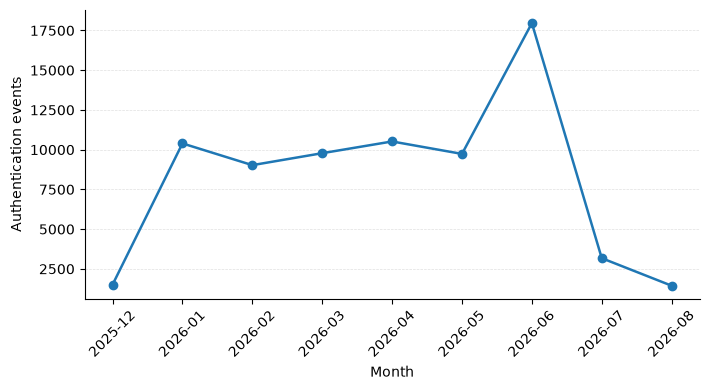

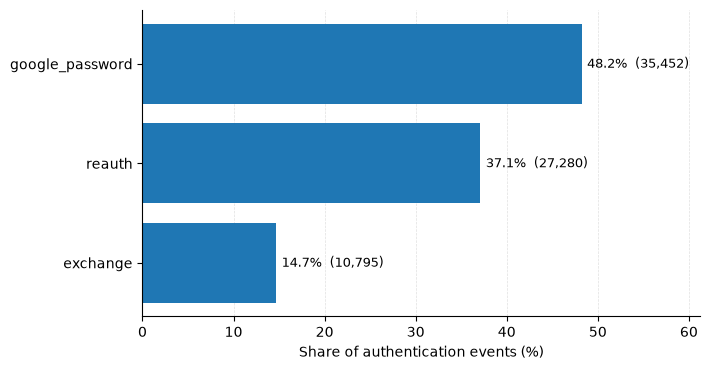

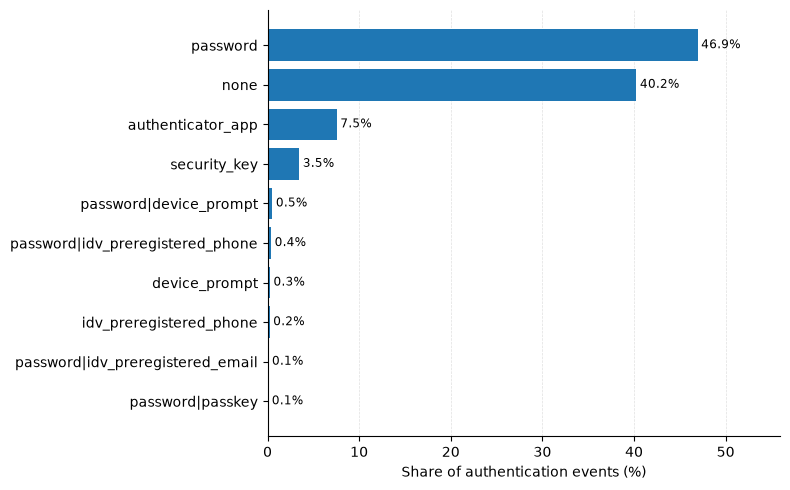

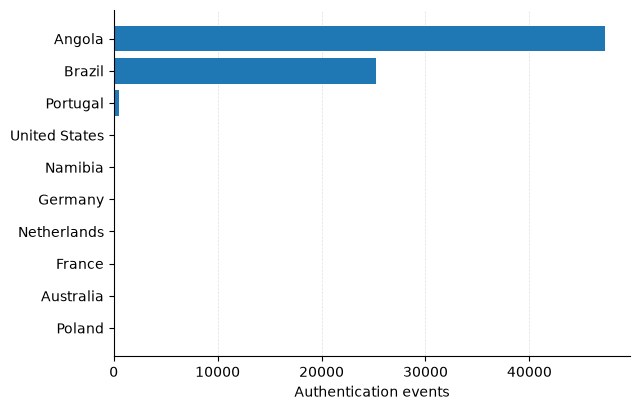

In [31]:
# Figure 1 — Monthly number of public authentication events
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(
    monthly_table["year_month"],
    monthly_table["events"],
    marker="o",
    linewidth=1.8,
)
ax.set_xlabel("Month")
ax.set_ylabel("Authentication events")
ax.tick_params(axis="x", rotation=45)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.4)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "monthly_authentication_events.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "monthly_authentication_events.png", dpi=600, bbox_inches="tight")
plt.show()


# Figure 2 — Login type distribution
plot_login = login_type_table.copy()
total_events = plot_login["events"].sum()
plot_login["percentage"] = plot_login["events"] / total_events * 100
plot_login = plot_login.sort_values("percentage", ascending=True)

fig, ax = plt.subplots(figsize=(7.2, 3.8))
bars = ax.barh(
    plot_login["login_type"],
    plot_login["percentage"],
)

for bar, pct, count in zip(
    bars,
    plot_login["percentage"],
    plot_login["events"],
):
    ax.text(
        bar.get_width() + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%  ({count:,})",
        va="center",
        ha="left",
        fontsize=9,
    )

ax.set_xlabel("Share of authentication events (%)")
ax.set_ylabel("")
ax.set_xlim(0, plot_login["percentage"].max() + 13)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
ax.set_axisbelow(True)
fig.tight_layout()

fig.savefig(FIGURE_DIR / "login_type_distribution.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "login_type_distribution.png", dpi=600, bbox_inches="tight")
plt.show()


# Figure 3 — Most frequent raw challenge-method values
plot_challenge = (
    challenge_raw
    .head(10)
    .sort_values("percent", ascending=True)
)

fig, ax = plt.subplots(figsize=(8.0, 5.0))
bars = ax.barh(
    plot_challenge["login_challenge_method"],
    plot_challenge["percent"],
)

for bar, pct in zip(
    bars,
    plot_challenge["percent"],
):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=8.5,
    )

ax.set_xlabel("Share of authentication events (%)")
ax.set_ylabel("")
ax.set_xlim(0, plot_challenge["percent"].max() + 9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
ax.set_axisbelow(True)
fig.tight_layout()

fig.savefig(FIGURE_DIR / "challenge_method_distribution_top10.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "challenge_method_distribution_top10.png", dpi=600, bbox_inches="tight")
plt.show()


# Figure 4 — Most frequent countries
plot_country = country_table.head(10).sort_values("events", ascending=True)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(
    plot_country["ip_country"],
    plot_country["events"],
)
ax.set_xlabel("Authentication events")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
ax.set_axisbelow(True)
fig.tight_layout()

fig.savefig(FIGURE_DIR / "country_distribution_top10.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "country_distribution_top10.png", dpi=600, bbox_inches="tight")
plt.show()


No Lorenz/Gini figure is generated here because the manuscript already contains that visualization. The Gini statistic itself remains computed above so the reported numerical result can be reproduced from the public release.

## 11. Export a compact public statistics file

In [ ]:
public_statistics = {
    "dataset_name": "HEIAuthRisk",
    "dataset_version": "1.0",
    "public_sha256": public_sha256,
    "events": int(n_events),
    "actors": int(n_actors),
    "public_attributes": int(len(public.columns)),
    "public_time_hour_min": public_time_min.isoformat(),
    "public_time_hour_max": public_time_max.isoformat(),
    "singleton_users": n_singleton,
    "recurrent_users": n_recurrent,
    "events_with_prior_history": with_history,
    "events_without_prior_history": without_history,
    "provider_suspicious_0": not_flagged,
    "provider_suspicious_1": flagged,
    "provider_suspicious_pct": float(flagged_pct),
    "actor_events_q1": float(q1),
    "actor_events_median": float(median),
    "actor_events_q3": float(q3),
    "actor_events_max": int(actor_counts.max()),
    "activity_gini": float(gini_coefficient(actor_counts)),
    "top_1pct_actor_event_share_pct": float(actor_counts.nlargest(top_1_n).sum() / n_events * 100),
    "top_10pct_actor_event_share_pct": float(actor_counts.nlargest(top_10_n).sum() / n_events * 100),
    "known_country_values": int(public["ip_country"].nunique(dropna=True)),
    "missing_country_events": int(public["ip_country"].isna().sum()),
}

stats_file = OUTPUT_DIR / "article1_public_statistics.json"
stats_file.write_text(
    json.dumps(public_statistics, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print(json.dumps(public_statistics, ensure_ascii=False, indent=2))
print(f"\nSaved: {stats_file}")

{
  "dataset_name": "HEIAuthRisk",
  "dataset_version": "2.0",
  "public_sha256": "47be2f74f1c1db3f1dbed2cf4343ca099de9a1ca59373c1b5eff2686688073ec",
  "events": 73526,
  "actors": 12190,
  "public_attributes": 42,
  "public_time_hour_min": "2025-12-19T19:00:00+00:00",
  "public_time_hour_max": "2026-08-12T16:00:00+00:00",
  "singleton_users": 347,
  "recurrent_users": 11843,
  "events_with_prior_history": 61336,
  "events_without_prior_history": 12190,
  "provider_suspicious_0": 66330,
  "provider_suspicious_1": 7196,
  "provider_suspicious_pct": 9.78701411745505,
  "actor_events_q1": 3.0,
  "actor_events_median": 3.0,
  "actor_events_q3": 4.0,
  "actor_events_max": 1847,
  "activity_gini": 0.5375532190239156,
  "top_1pct_actor_event_share_pct": 29.930908794168047,
  "top_10pct_actor_event_share_pct": 52.9894187090281,
  "known_country_values": 23,
  "missing_country_events": 1
}

Saved: outputs\article_one_results\article1_public_statistics.json


## 12. Public analysis completion

In [28]:
print("=" * 72)
print("PUBLIC RESULTS ANALYSIS: COMPLETE")
print(f"Dataset analyzed: {PUBLIC_FILE.name}")
print(f"Outputs written to: {OUTPUT_DIR.resolve()}")
print("No restricted dataset was loaded or required.")
print("=" * 72)

PUBLIC RESULTS ANALYSIS: COMPLETE
Dataset analyzed: suspicious_logins_public_v2.csv
Outputs written to: E:\Developer\HEIAuthRisk\public\notebooks\outputs\article_one_results
No restricted dataset was loaded or required.
